# Hotel Reservation Cancellation Prediction

## Read and Load Dataset

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                            roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

In [25]:
df = pd.read_csv("Hotel Reservations.csv")
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [26]:
print(df.shape)
print(df.columns.tolist())
df.info()

(36275, 19)
['Booking_ID', 'no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space', 'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'market_segment_type', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests', 'booking_status']
<class 'pandas.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  str    
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_

The dataset has one row per hotel booking (36,275 rows, 19 columns).

## Defining the Task
- **Type:** Supervised learning, binary classification.
- **Label:** `booking_status` (`Canceled` = 1, `Not_Canceled` = 0).
- **Features:** Booking details (lead time, price, party size, meal plan, room type, market segment, special requests, guest history, arrival date).
- **Task:** Predict whether a booking will be canceled to plan for overbooking, targeted deposits or reminders, and revenue forecasts.

## Explore Data

In [27]:
print('Nulls:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate Booking_IDs:', df['Booking_ID'].duplicated().sum())
df.describe().T

Nulls: 0
Duplicate rows: 0
Duplicate Booking_IDs: 0


,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.844962,0.518715,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.105279,0.402648,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.810724,0.870644,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.204300,1.410905,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.030986,0.173281,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.232557,85.930817,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.820427,0.383836,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.423653,3.069894,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.596995,8.740447,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.025637,0.158053,0.0,0.0,0.00,0.0,1.0


In [28]:
print('Rooms with price = 0:', (df['avg_price_per_room'] == 0).sum())
print('Bookings with 0 adults:', (df['no_of_adults'] == 0).sum())
print(df[df['avg_price_per_room'] == 0]['market_segment_type'].value_counts())

Rooms with price = 0: 545
Bookings with 0 adults: 139
market_segment_type
Complementary    354
Online           191
Name: count, dtype: int64


There are no nulls or duplicates. Most zero-price rooms are in the Complementary segment (354 of 545), so they appear legitimate. Zero-adult bookings are rare (139) but still plausible, so they are also kept.

### Target distribution

booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64
booking_status
Not_Canceled    0.672
Canceled        0.328
Name: proportion, dtype: float64


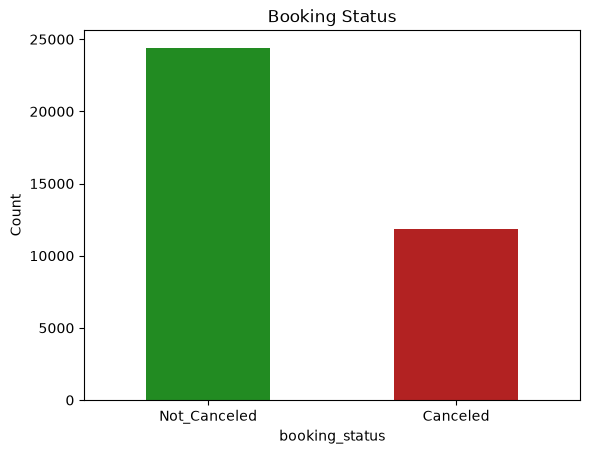

In [29]:
print(df['booking_status'].value_counts())
print(df['booking_status'].value_counts(normalize=True).round(3))
df['booking_status'].value_counts().plot(kind='bar', color=['#228B22', '#b22222'])
plt.title('Booking Status'); plt.ylabel('Count'); plt.xticks(rotation=0); plt.show()

~33% of bookings are canceled and 67% are not. It's imbalanced, and benefits from class weighting and reporting recall/F1.

### Features Graphed

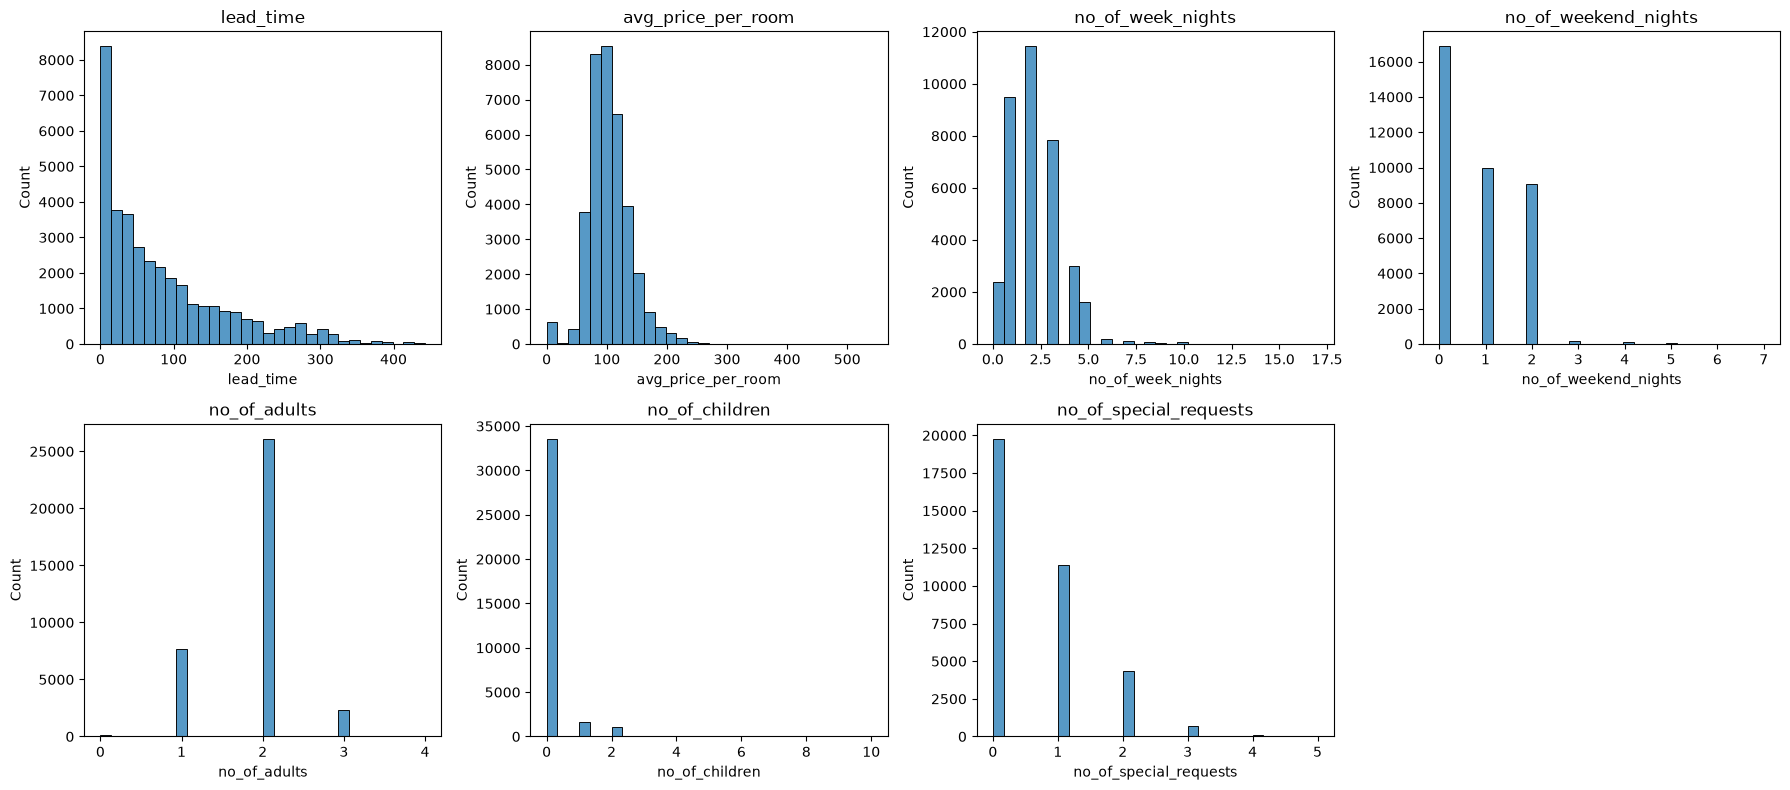

In [30]:
num_cols = ['lead_time', 'avg_price_per_room', 'no_of_week_nights', 'no_of_weekend_nights',
            'no_of_adults', 'no_of_children', 'no_of_special_requests']
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.flatten()
for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=30, ax=axes[i]); axes[i].set_title(c)
axes[-1].axis('off'); plt.tight_layout(); plt.show()

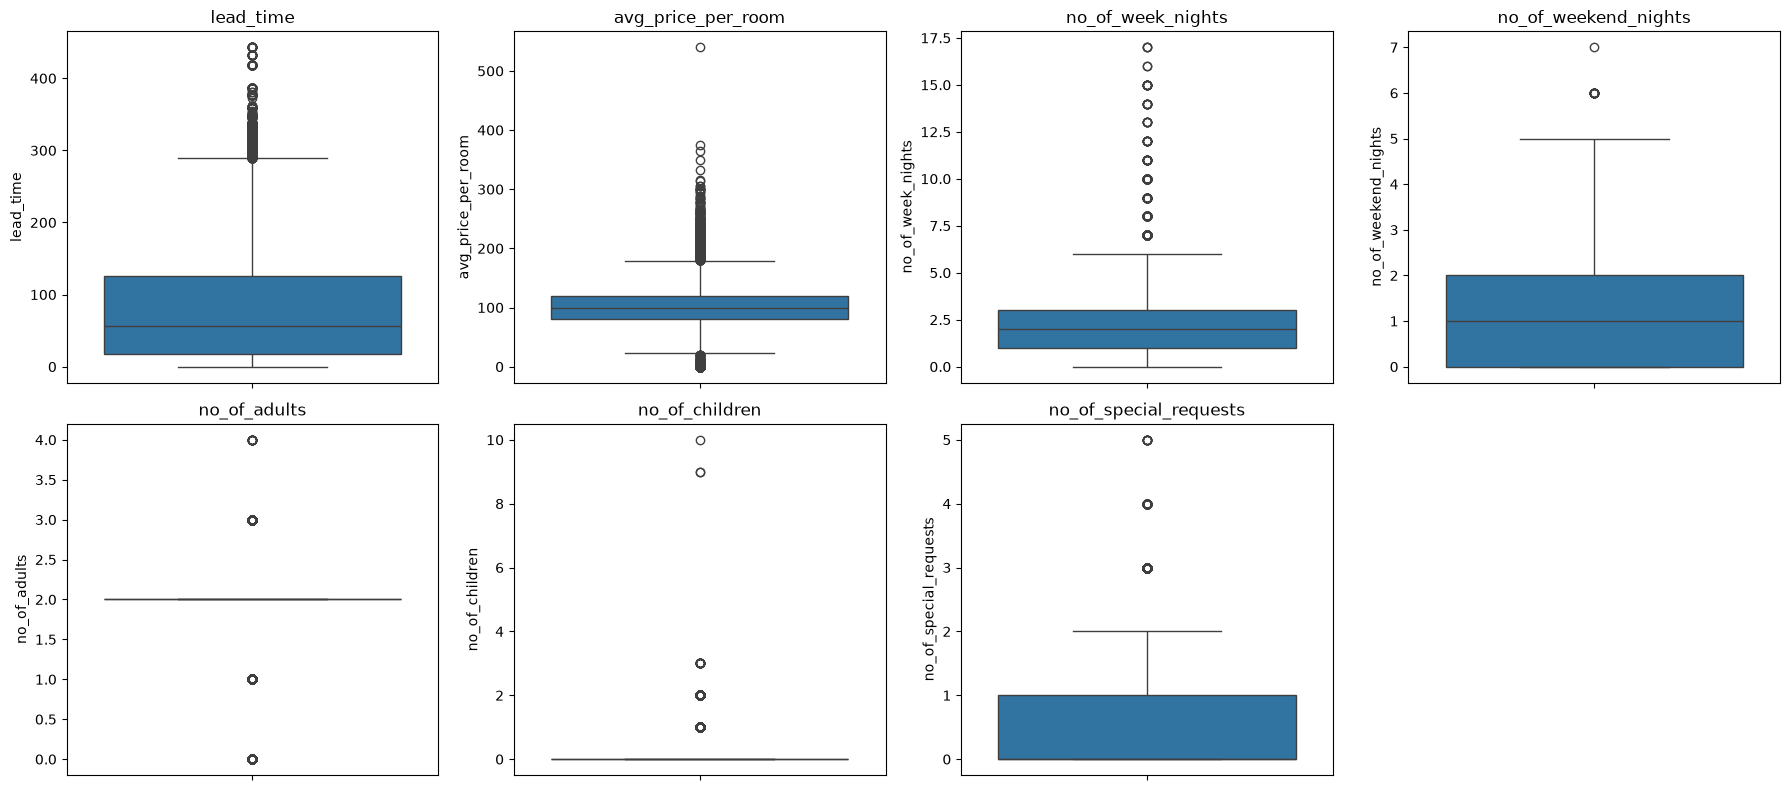

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.flatten()
for i, c in enumerate(num_cols):
    sns.boxplot(y=df[c], ax=axes[i]); axes[i].set_title(c)
axes[-1].axis('off'); plt.tight_layout(); plt.show()

In [32]:
for c in ['lead_time', 'avg_price_per_room', 'no_of_week_nights', 'no_of_weekend_nights']:
    Q1, Q3 = df[c].quantile([.25, .75]); IQR = Q3 - Q1
    n = ((df[c] < Q1 - 1.5*IQR) | (df[c] > Q3 + 1.5*IQR)).sum()
    print(f"{c}: {n} outliers ({n/len(df):.1%}), skew = {df[c].skew():.2f}")

lead_time: 1331 outliers (3.7%), skew = 1.29
avg_price_per_room: 1696 outliers (4.7%), skew = 0.67
no_of_week_nights: 324 outliers (0.9%), skew = 1.60
no_of_weekend_nights: 21 outliers (0.1%), skew = 0.74


`lead_time` is right-skewed (many short lead times, a long tail to 443 days). `avg_price_per_room` has high-price outliers (one at 540). Stay-length variables also have a long right tail. Skew and outliers can have a big influence on linear models. It will help to cap extreme values and log-transform `lead_time`.

### Features vs. cancellation

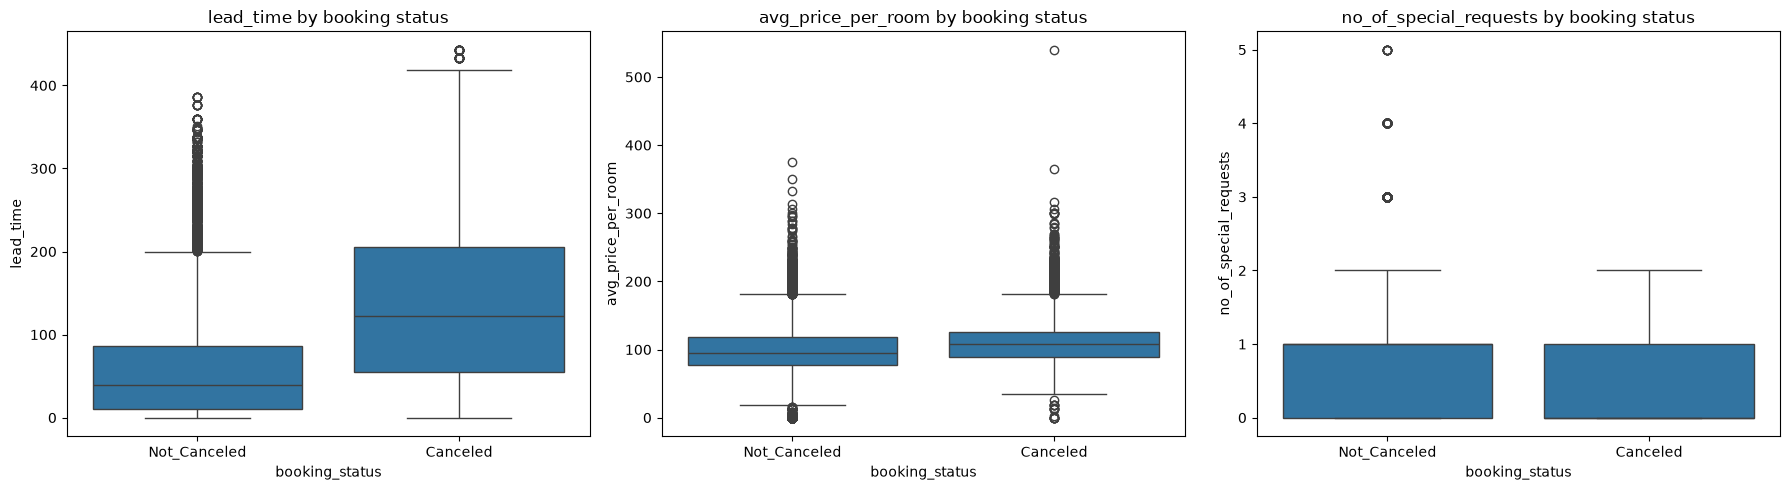

                lead_time  avg_price_per_room  no_of_special_requests
booking_status                                                       
Canceled           139.22              110.59                    0.33
Not_Canceled        58.93               99.93                    0.76


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ['lead_time', 'avg_price_per_room', 'no_of_special_requests']):
    sns.boxplot(data=df, x='booking_status', y=c, ax=ax); ax.set_title(f'{c} by booking status')
plt.tight_layout(); plt.show()
print(df.groupby('booking_status')[['lead_time', 'avg_price_per_room', 'no_of_special_requests']].mean().round(2))

Canceled bookings have a much longer lead time (~139 vs ~59 days), higher prices (~$111 vs ~$100), and far fewer special requests. Lead time appears like the strongest signal.

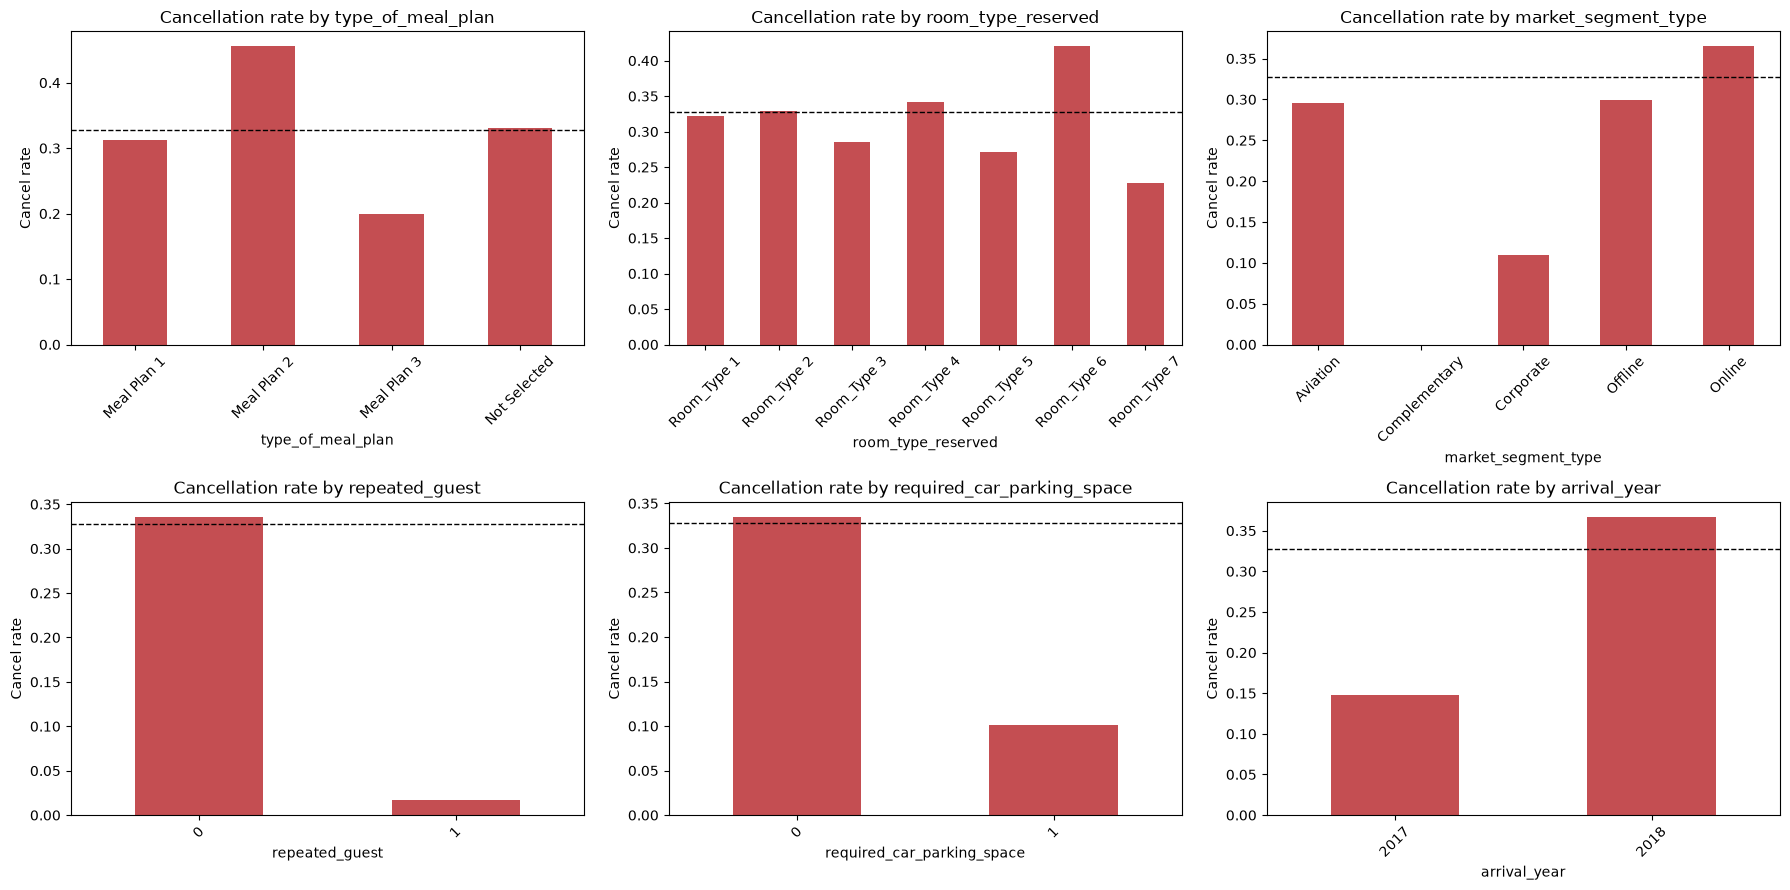

In [34]:
cat_cols = ['type_of_meal_plan', 'room_type_reserved', 'market_segment_type', 'repeated_guest',
            'required_car_parking_space', 'arrival_year']
fig, axes = plt.subplots(2, 3, figsize=(18, 9)); axes = axes.flatten()
for ax, c in zip(axes, cat_cols):
    rate = df.groupby(c)['booking_status'].apply(lambda s: (s == 'Canceled').mean())
    rate.plot(kind='bar', ax=ax, color='#c44e52'); ax.set_title(f'Cancellation rate by {c}')
    ax.set_ylabel('Cancel rate'); ax.axhline(0.328, color='k', ls='--', lw=1); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

Online bookings cancel most (~37%), followed by Aviation and Offline (~30%); Corporate bookings rarely cancel (~11%) and Complementary stays never do. Repeat guests (~2%) and bookings with a parking space (~10%) rarely cancel.

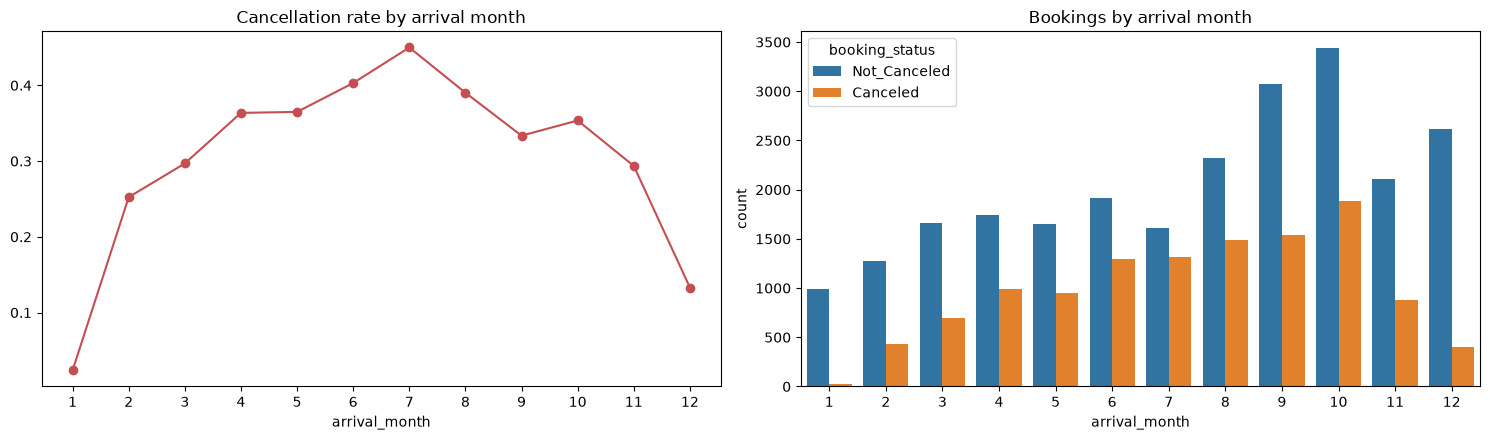

In [35]:
m = df.groupby('arrival_month')['booking_status'].apply(lambda s: (s == 'Canceled').mean())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
m.plot(marker='o', ax=ax[0], color='#c44e52'); ax[0].set_title('Cancellation rate by arrival month'); ax[0].set_xticks(range(1, 13))
sns.countplot(data=df, x='arrival_month', hue='booking_status', ax=ax[1]); ax[1].set_title('Bookings by arrival month')
plt.tight_layout(); plt.show()

In [36]:
pd.crosstab(df['no_of_special_requests'], df['booking_status'], normalize='index').round(3)

booking_status,Canceled,Not_Canceled
no_of_special_requests,,
0,0.432,0.568
1,0.238,0.762
2,0.146,0.854
3,0.000,1.000
4,0.000,1.000
5,0.000,1.000


Cancellation varies with season (peaking in July at ~45%, lowest in December/January), and the cancel rate drops steadily as the number of special requests rises, which suggests guests who customize their stay are more committed.

### Correlation Heatmap

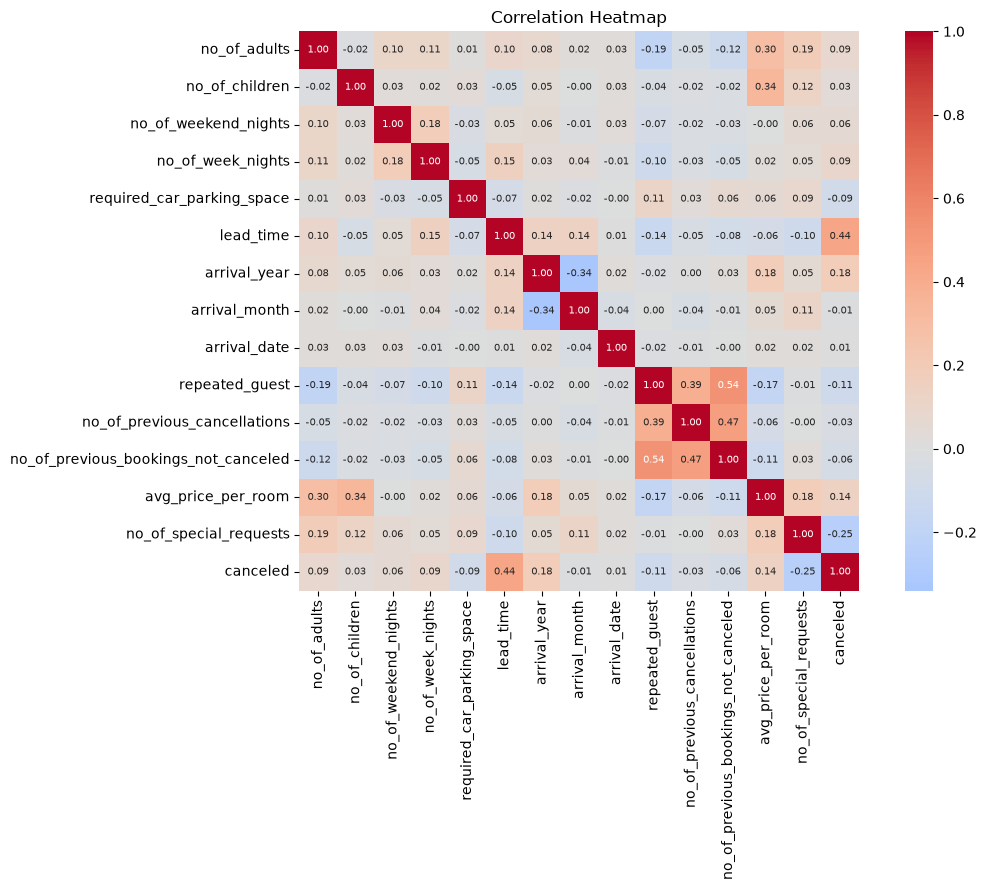

lead_time                               0.439
no_of_special_requests                 -0.253
arrival_year                            0.180
avg_price_per_room                      0.143
repeated_guest                         -0.107
no_of_week_nights                       0.093
no_of_adults                            0.087
required_car_parking_space             -0.086
no_of_weekend_nights                    0.062
no_of_previous_bookings_not_canceled   -0.060
no_of_previous_cancellations           -0.034
no_of_children                          0.033
arrival_month                          -0.011
arrival_date                            0.011
Name: canceled, dtype: float64


In [37]:
tmp = df.copy(); tmp['canceled'] = (tmp['booking_status'] == 'Canceled').astype(int)
corr = tmp.corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, annot_kws={'size': 7})
plt.title('Correlation Heatmap'); plt.tight_layout(); plt.show()
print(corr['canceled'].drop('canceled').sort_values(key=abs, ascending=False).round(3))

Strongest correlations with cancellation are `lead_time` (+0.44), `no_of_special_requests` (-0.25), `arrival_year` (+0.18), `avg_price_per_room` (+0.14), and `repeated_guest` / `required_car_parking_space` (about -0.1).

## Project Plan
| Step | Task | Status |
|---|---|---|
| 1 | Load data, define problem | Done |
| 2 | EDA and visualizations | Done |
| 3 | Data preparation (drop ID, cap outliers, log-transform, one-hot encode, split, scale) | Done |
| 4 | **Model 1:** Logistic Regression baseline (interpretable) | Done |
| 5 | **Model 2:** Decision Tree, tuning `max_depth` and `min_samples_leaf` with a validation curve | Planned |
| 6 | **Model 3:** Ensembles (Random Forest, Bagging, AdaBoost) to capture non-linear effects | Planned |
| 7 | **Model 4:** KNN and Neural Network (Keras) for comparison | Planned |
| 8 | Hyperparameter tuning with `GridSearchCV` (5-fold, scored on F1) and threshold tuning | Planned |
| 9 | Compare all models on one table (accuracy, precision, recall, F1, AUC), pick the final model, analyze feature importance | Planned |

**Evaluation approach:** Stratified 80/20 train/test split, 5-fold CV on the training set, and train-vs-test gaps to diagnose over/underfitting. Primary metrics are F1 and recall on the Canceled class, plus ROC AUC.

## Data Preparation

In [38]:
data = df.drop(columns=['Booking_ID']).copy()
data['booking_status'] = data['booking_status'].map({'Not_Canceled': 0, 'Canceled': 1})
data['booking_status'].value_counts()

booking_status
0    24390
1    11885
Name: count, dtype: int64

`Booking_ID` is dropped (identifier only) and the label is encoded as 1 = Canceled.

In [39]:
# Feature engineering total nights and total guests
data['total_nights'] = data['no_of_weekend_nights'] + data['no_of_week_nights']
data['total_guests'] = data['no_of_adults'] + data['no_of_children']

# Cap extreme outliers at 1st/99th percentile (winsorize)
cap_cols = ['avg_price_per_room', 'no_of_week_nights', 'no_of_weekend_nights', 'total_nights', 'no_of_children']
for c in cap_cols:
    lo, hi = data[c].quantile([.01, .99])
    data[c] = data[c].clip(lo, hi)

# Log-transform right-skewed lead time
print('lead_time skew before:', round(data['lead_time'].skew(), 2))
data['lead_time'] = np.log1p(data['lead_time'])
print('lead_time skew after: ', round(data['lead_time'].skew(), 2))

lead_time skew before: 1.29
lead_time skew after:  -0.83


In [40]:
cat_to_encode = ['type_of_meal_plan', 'room_type_reserved', 'market_segment_type']
data = pd.get_dummies(data, columns=cat_to_encode, drop_first=True, dtype=int)
print(data.shape)
data.head()

(36275, 30)


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,...,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
0,2,0,1,2,0,5.416100,2017,10,2,0,...,0,0,0,0,0,0,0,0,1,0
1,2,0,2,3,0,1.791759,2018,11,6,0,...,0,0,0,0,0,0,0,0,0,1
2,1,0,2,1,0,0.693147,2018,2,28,0,...,0,0,0,0,0,0,0,0,0,1
3,2,0,0,2,0,5.356586,2018,5,20,0,...,0,0,0,0,0,0,0,0,0,1
4,2,0,1,1,0,3.891820,2018,4,11,0,...,0,0,0,0,0,0,0,0,0,1


In [41]:
X = data.drop(columns='booking_status')
y = data['booking_status']
print('examples:', X.shape[0], '| features:', X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print('Train cancel rate:', round(y_train.mean(), 3), '| Test cancel rate:', round(y_test.mean(), 3))

examples: 36275 | features: 29
(29020, 29) (7255, 29)
Train cancel rate: 0.328 | Test cancel rate: 0.328


In [42]:
# Fit the scaler on the training set
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

A stratified split keeps the cancel rate equal in train and test. The scaler is fit on the training data only, so no test information leaks into training. Class imbalance is handled with `class_weight='balanced'` in the model rather than resampling.

## Model 1: Logistic Regression

In [43]:
log_reg = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
log_reg.fit(X_train_s, y_train)

y_pred_train = log_reg.predict(X_train_s)
y_pred_test = log_reg.predict(X_test_s)
y_prob_test = log_reg.predict_proba(X_test_s)[:, 1]

In [44]:
def metrics(y_true, y_pred, y_prob):
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred), 'ROC AUC': roc_auc_score(y_true, y_prob)}

results = pd.DataFrame({
    'Train': metrics(y_train, y_pred_train, log_reg.predict_proba(X_train_s)[:, 1]),
    'Test': metrics(y_test, y_pred_test, y_prob_test)}).T.round(4)
results

,Accuracy,Precision,Recall,F1,ROC AUC
Train,0.7585,0.5996,0.7914,0.6823,0.8534
Test,0.7666,0.6093,0.8023,0.6926,0.8616


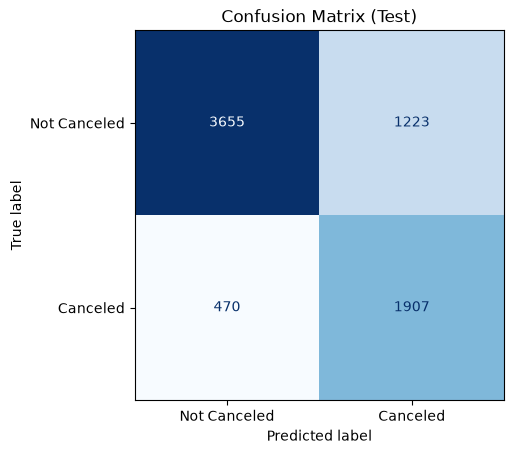

TN=3655  FP=1223  FN=470  TP=1907


In [45]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_test), display_labels=['Not Canceled', 'Canceled']).plot(cmap='Blues', colorbar=False)
plt.title('Confusion Matrix (Test)'); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')

## Model Results and Next Steps

In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = cross_val_score(LogisticRegression(max_iter=2000, class_weight='balanced'), X_train_s, y_train, cv=cv, scoring='f1')
print('5-fold CV F1:', cv_f1.round(4), '| mean =', cv_f1.mean().round(4), '| std =', cv_f1.std().round(4))
print('Train F1:', round(f1_score(y_train, y_pred_train), 4), '| Test F1:', round(f1_score(y_test, y_pred_test), 4))

5-fold CV F1: [0.6799 0.6884 0.69   0.6801 0.6719] | mean = 0.6821 | std = 0.0065
Train F1: 0.6823 | Test F1: 0.6926


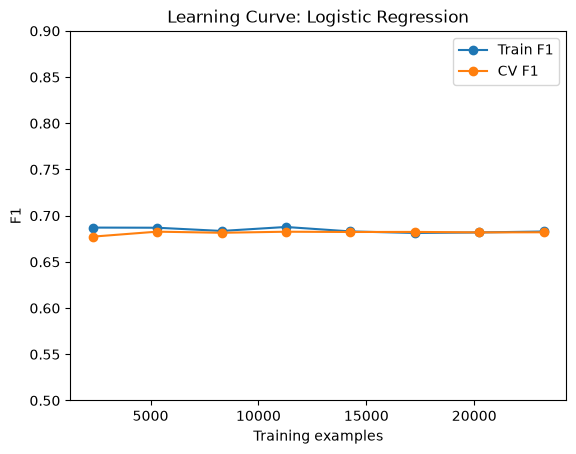

In [47]:
sizes, tr_sc, va_sc = learning_curve(LogisticRegression(max_iter=2000, class_weight='balanced'), X_train_s, y_train,
                                     train_sizes=np.linspace(0.1, 1, 8), cv=cv, scoring='f1')
plt.plot(sizes, tr_sc.mean(1), 'o-', label='Train F1'); plt.plot(sizes, va_sc.mean(1), 'o-', label='CV F1')
plt.xlabel('Training examples'); plt.ylabel('F1'); plt.title('Learning Curve: Logistic Regression'); plt.legend(); plt.ylim(0.5, 0.9); plt.show()

### Discussion
**Results.** The model reaches about 77% test accuracy, F1 of ~0.69, ROC AUC of ~0.86, and ~0.80 recall on canceled bookings (1,907 of 2,377 caught; 470 missed). Class weighting trades precision (~0.61) for recall. The AUC of 0.86 (train 0.85) shows the model ranks cancellations well overall, so threshold tuning can shift the precision/recall balance. 1,223 bookings that were kept get flagged as cancellations.

**Fit evidence.** Train and test scores are very similar (train F1 0.682, test F1 0.693), and F1 is stable across folds (mean 0.682, std 0.007). The learning curve shows train and validation curves already converged and flat. There is no overfitting. The flat, converged curves at a moderate score indicate mild underfitting.

**Next steps.**
1. Try other models (Decision Tree, Random Forest, etc)
2. Tune hyperparameters with `GridSearchCV` and watch the train-test gap, control with `max_depth`, `min_samples_leaf`.
3. Tune the decision threshold to balance recall against precision based on what an empty room vs. an unneeded overbooking costs.
4. Add engineered features (e.g., arrival weekday, price per guest) and compare against the baseline.
5. Examine feature importance on the final model to give the hotel actionable levers (e.g., lead time, market segment, special requests).

## Remaining Work Plan & Timeline
| When | Tasks |
|---|---|
| Before break (Nov 20–25) | Add ROC AUC; tune LR regularization `C`; Decision Tree with pruning (`max_depth`, `min_samples_leaf`, `max_leaf_nodes`) and a validation curve; KNN (choose K with CV) |
| Thanksgiving break (Nov 26–29) | Random Forest, Bagging, AdaBoost, Gradient Boosting; SVM (RBF); Keras NN with early stopping + dropout |
| Nov 30 – Dec 1 | `GridSearchCV` (5-fold, F1) on the top 2–3 models; decision-threshold tuning; feature selection (forward/backward, test dropping `arrival_year`); feature importance |
| Dec 2 – Dec 3 | One comparison table (Acc, Prec, Recall, F1, AUC, train-test gap), pick the final model, write the conclusions, clean up the notebook |

**Fit diagnosis for every model:** train vs. CV vs. test scores and learning curves, framed as bias/variance (LR = high bias; we expect unpruned trees and small-K KNN to be high variance).